# 02 · Tratamento — bronze → silver → gold

**Tech Challenge Fase 4 · POSTECH DTAT — Data Analytics · Grupo 12**

Este notebook **documenta e reexecuta** o que `src/prepara_dados.py` faz. Ele não é um
segundo pipeline: é a justificativa do pipeline. Cada passo aparece aqui com a
**decisão tomada**, a **alternativa descartada** e a **medição** que separa as duas.
Na última seção o script oficial é chamado e as camadas são comparadas byte a byte
contra o que este notebook reproduziu em memória.

## Objetivo
Explicar por que a base analítica tem **1.348 produtos** e não 1.465 — e provar que
qualquer pessoa que rode o script chega exatamente na mesma base.

## Entradas
| Camada | Arquivo | Papel |
|---|---|---|
| bronze | `00_data/bronze/amazon.csv` | origem intocada, 1.465 × 16, tudo texto. **Somente leitura** |

## Saídas
| Camada | Arquivo | Conteúdo |
|---|---|---|
| silver | `00_data/silver/produtos.csv` | 1.351 × 9, tipado, deduplicado, sem colunas pessoais — **versionado** |
| silver | `00_data/silver/produtos_texto.csv` | 1.351 × 5, texto livre — **fora do git** (nomes de pessoas reais nas avaliações) |
| gold | `00_data/gold/base_analitica.csv` | 1.348 × 17, com os derivados |
| gold | `00_data/gold/reviews.csv` | 9.255 reviews distintos |
| figuras | `02_results/images/fig_trat_01_empates_deduplicacao.png`, `fig_trat_02_impacto_regra_dedup.png` | |
| tabelas | `02_results/tables/tab09_*.csv` … `tab11_*.csv` | |

## Pontos que este notebook é obrigado a fechar
- **(a)** a regra de deduplicação determinística e **por que o desempate é necessário**;
- **(b)** o que muda **sem** o desempate;
- **(c)** por que **não** se adotou a primeira ocorrência;
- **(d)** a remoção de `user_id` e `user_name` (**T7**);
- **(e)** a reconciliação **1.465 → 1.351 → 1.350 → 1.349 → 1.348**.

## Regras transversais em vigor neste notebook
- **T3** — todo número declara a base e o *n*.
- **T4** — linguagem de associação, nunca de causa.
- **T6** — `rating_count` é **volume de avaliações**. Nunca vendas, receita ou demanda.
- **T7** — `user_id` e `user_name` não atravessam o bronze. Não aparecem em nenhuma saída.
- **T8** — o corpus textual declara a unidade, deduplica por `review_id` e cita o truncamento em 8.
- **T9** — toda figura usa a paleta v06 aplicada por `src/paleta.py`. Nenhuma cor escolhida à mão.

## Limitações que o tratamento *não* resolve
- **L4** — a base não tem venda, receita, estoque nem data. Nenhum tratamento cria essas variáveis.
- **L5** — valores monetários em **rupia indiana**, publicados **sem símbolo** e **sem conversão**.
- **L6** — as 114 linhas excedentes são o objeto desta seção; o tratamento as resolve, não as apaga.
- **L1** — o truncamento em 8 avaliações por produto é da origem. A deduplicação do corpus
  não recupera o que o marketplace não exibiu.

## Como rodar
```bash
python -m nbconvert --to notebook --execute --inplace 01_notebooks/02_tratamento.ipynb
```

## 0 · Ambiente

Primeira célula de código de todo notebook do projeto. Sem `aplicar()` os gráficos saem
na paleta padrão do matplotlib — descumprimento de **T9**.

A raiz do repositório é resolvida subindo diretórios até encontrar o bronze, e não por
caminho fixo: isso deixa o notebook executável tanto a partir de `01_notebooks/` quanto
da raiz, o que importa porque o `nbconvert` do CI nem sempre usa o mesmo diretório de
trabalho do Jupyter interativo.

In [1]:
# T9 — a paleta é aplicada por ferramenta, nunca cor a cor.
import sys; sys.path.insert(0, "../src")

import hashlib
import os
import subprocess
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

# Raiz do repositório: sobe até encontrar o bronze. Tolera cwd = raiz ou = 01_notebooks/.
RAIZ = Path.cwd().resolve()
while not (RAIZ / "00_data" / "bronze" / "amazon.csv").exists() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
if not (RAIZ / "00_data" / "bronze" / "amazon.csv").exists():
    raise FileNotFoundError(
        "bronze não encontrado. Baixe amazon.csv de "
        "https://www.kaggle.com/datasets/karkavelrajaj/amazon-sales-dataset "
        "e coloque em 00_data/bronze/."
    )
sys.path.insert(0, str(RAIZ / "src"))

from paleta import rodape, confere_visual, CATEGORICA, CHAMADAS, ESTRUTURA, aplicar  # noqa: E402
aplicar()

BRONZE = RAIZ / "00_data" / "bronze" / "amazon.csv"
SILVER = RAIZ / "00_data" / "silver" / "produtos.csv"
SILVER_TXT = RAIZ / "00_data" / "silver" / "produtos_texto.csv"
# O silver em disco é dividido por LGPD: produtos.csv (9 colunas, versionado)
# e produtos_texto.csv (texto livre, fora do versionamento). Ver 00_data/README.md.
TEXTO_LIVRE = ["about_product", "review_title", "review_content"]
GOLD = RAIZ / "00_data" / "gold" / "base_analitica.csv"
GOLD_REV = RAIZ / "00_data" / "gold" / "reviews.csv"
IMAGENS = RAIZ / "02_results" / "images"
TABELAS = RAIZ / "02_results" / "tables"
IMAGENS.mkdir(parents=True, exist_ok=True)
TABELAS.mkdir(parents=True, exist_ok=True)

# Rodapé obrigatório de figura (T3): fonte, base e n em toda imagem gerada aqui.
def sha256(caminho):
    with open(caminho, "rb") as fh:
        return hashlib.sha256(fh.read()).hexdigest()

print("raiz do repositório :", RAIZ.name + "/")
print("paleta v06 aplicada :", CATEGORICA)
print("pandas", pd.__version__, "· numpy", np.__version__)

raiz do repositório : Techchallenge4-G12/
paleta v06 aplicada : ['#F2C14E', '#3F5A7A', '#9AA5B1', '#DC6C09', '#1F6F6B', '#5B6770']
pandas 3.0.6 · numpy 2.5.3


## 1 · Bronze — leitura, e prova de que nada foi escrito

A camada bronze existe por uma razão só: **o CSV de origem nunca é alterado**. Ele é lido e
todo resultado vai para outra camada. Sem isso não há como responder "o número mudou porque
o dado mudou, ou porque o código mudou?".

A garantia é o **SHA-256**. Se o hash não bater com o registrado em `src/prepara_dados.py`,
nenhum número do material vale sobre este arquivo — e o notebook para.

**Decisão:** ler com `dtype=str`.
**Alternativa descartada:** deixar o pandas inferir tipo. Ela foi descartada porque a
inferência silenciosamente transforma `rating_count` em `float` (por causa dos nulos),
engole o `|` do campo `rating` como `NaN` sem registro, e perde a chance de *contar* as
falhas de conversão — que são justamente parte da reconciliação que precisamos publicar.

In [2]:
SHA_BRONZE = "4ba126c4ba8edd35e62e94ce1c853073d832de380184ab4f5f97d1e314882c77"

try:
    sha = sha256(BRONZE)
except OSError as erro:                      # disco, permissão, arquivo em uso
    raise RuntimeError(f"não foi possível ler o bronze: {erro}") from erro

print("BRONZE :", BRONZE.relative_to(RAIZ))
print("SHA-256:", sha)
assert sha == SHA_BRONZE, (
    "o bronze não é a base canônica — nenhum número do material vale sobre ele."
)
print("integridade conferida · este notebook NUNCA escreve nesta camada")

bronze = pd.read_csv(BRONZE, dtype=str)
n_bruta = len(bronze)
print(f"\nbase Bruta: {n_bruta} linhas × {bronze.shape[1]} colunas, todas string")
print("colunas:", list(bronze.columns))

BRONZE : 00_data/bronze/amazon.csv
SHA-256: 4ba126c4ba8edd35e62e94ce1c853073d832de380184ab4f5f97d1e314882c77
integridade conferida · este notebook NUNCA escreve nesta camada

base Bruta: 1465 linhas × 16 colunas, todas string
colunas: ['product_id', 'product_name', 'category', 'discounted_price', 'actual_price', 'discount_percentage', 'rating', 'rating_count', 'about_product', 'user_id', 'user_name', 'review_id', 'review_title', 'review_content', 'img_link', 'product_link']


### 1.1 · Qualidade da origem, antes de qualquer tratamento

Medir antes de tratar. O que esta célula apura é o que justifica cada decisão adiante —
e é também o que entra na limitação **L6**.

In [3]:
# O marcador de moeda da origem entra como escape unicode: a premissa do
# projeto é que o símbolo de rupia não apareça em rótulo, visual ou texto
# publicado. Aqui ele é só alvo de remoção.
MOEDA_ORIGEM = "\u20b9"

def para_numero(serie, remover):
    """Converte texto em número removendo os caracteres de formatação da origem.

    `remover` traz o símbolo de moeda, o separador de milhar e o `%`. Esses caracteres
    são **da origem**, que é texto; nenhum valor monetário sai deste notebook com símbolo
    (L5 — rupia indiana, sem conversão).
    Falha de conversão vira NaN e é contada, nunca descartada em silêncio.
    """
    saida = serie.astype(str)
    for ch in remover:
        saida = saida.str.replace(ch, "", regex=False)
    return pd.to_numeric(saida, errors="coerce")


b = bronze.copy()
b["preco_desc"] = para_numero(b.discounted_price, [MOEDA_ORIGEM, ","])
b["preco_tab"] = para_numero(b.actual_price, [MOEDA_ORIGEM, ","])
b["desconto"] = para_numero(b.discount_percentage, ["%"])
b["avaliacoes"] = para_numero(b.rating_count, [","])     # T6 — VOLUME DE AVALIAÇÕES
b["nota"] = pd.to_numeric(b.rating, errors="coerce")
# O marcador também está DENTRO de um nome de produto (o teclado com a tecla da rupia).
# A silver e a gold são versionadas, então o nome sai com a palavra no lugar do glifo —
# a mesma regra de src/prepara_dados.py, e o bronze não muda (L5, exceção 2).
b["product_name"] = b.product_name.str.replace(MOEDA_ORIGEM, "rupia", regex=False)
b["_ordem"] = np.arange(len(b))                          # índice de linha na origem

ocorrencias = b.product_id.value_counts()
repetidos = ocorrencias[ocorrencias > 1]

qualidade = pd.DataFrame([
    ("linhas na origem", n_bruta),
    ("linhas integralmente duplicadas", int(bronze.duplicated().sum())),
    ("product_id distintos", int(b.product_id.nunique())),
    ("product_id com mais de uma ocorrência", int(len(repetidos))),
    ("linhas excedentes por product_id", int((ocorrencias - 1).sum())),
    ("falha de conversão · rating", int(b.nota.isna().sum())),
    ("falha de conversão · rating_count", int(b.avaliacoes.isna().sum())),
    ("falha de conversão · preço de tabela", int(b.preco_tab.isna().sum())),
    ("falha de conversão · preço com desconto", int(b.preco_desc.isna().sum())),
    ("falha de conversão · desconto", int(b.desconto.isna().sum())),
    ("preço com desconto acima do preço de tabela", int((b.preco_desc > b.preco_tab).sum())),
], columns=["verificação", "valor"])

print("QUALIDADE DA ORIGEM · base Bruta, n = 1.465")
print(qualidade.to_string(index=False))
print("\nvalores que falharam na conversão de rating     :",
      bronze.loc[b.nota.isna(), "rating"].tolist())
print("valores que falharam na conversão de rating_count:",
      bronze.loc[b.avaliacoes.isna(), "rating_count"].tolist())

QUALIDADE DA ORIGEM · base Bruta, n = 1.465
                                verificação  valor
                           linhas na origem   1465
            linhas integralmente duplicadas      0
                       product_id distintos   1351
      product_id com mais de uma ocorrência     92
           linhas excedentes por product_id    114
                falha de conversão · rating      1
          falha de conversão · rating_count      2
       falha de conversão · preço de tabela      0
    falha de conversão · preço com desconto      0
              falha de conversão · desconto      0
preço com desconto acima do preço de tabela      0

valores que falharam na conversão de rating     : ['|']
valores que falharam na conversão de rating_count: [nan, nan]


**Leitura.** Não há uma única linha integralmente duplicada. O problema é outro: **114 linhas
excedentes** distribuídas em **92 `product_id`** — o mesmo produto coletado mais de uma vez,
com defasagem de segundos no contador de avaliações. Isso não é erro de cadastro nem produto
distinto; é a mesma coleta repetida. E as falhas de conversão são três, todas nominais:
um `rating` com o valor `|` e dois `rating_count` nulos.

Registre-se o que **não** aparece: nenhum preço com desconto acima do preço de tabela, e
nenhuma falha de conversão em preço ou desconto. A limpeza monetária é trivial — o trabalho
todo está na deduplicação.

## 2 · (a) A regra de deduplicação — e por que o desempate é obrigatório

### A regra
> Manter, por `product_id`, a ocorrência de **maior `rating_count`**;
> **no empate, a de menor índice de linha na origem**.

### Por que "maior `rating_count`" e não outra coisa
As ocorrências repetidas são a **mesma coleta em instantes diferentes**. O contador de
avaliações só cresce. Ficar com o maior valor é ficar com a leitura **mais recente** —
e portanto com o bloco de texto mais completo. Nenhuma outra coluna dá esse ordenamento
temporal: a base não tem data (**L4**).

### Por que o desempate é necessário — e não um preciosismo
Aqui está o ponto que a próxima célula mede. A regra "maior `rating_count`" **sozinha não
decide** a maioria dos casos: dos **92** `product_id` repetidos, só uma parte tem máximo
único. Nos demais o máximo **empata**, e sem um critério explícito o vencedor passa a
depender do algoritmo de ordenação — `sort_values` usa *quicksort* por padrão, que **não é
estável**. A base deixaria de ser reproduzível entre versões de biblioteca.

**Decisão:** o índice de linha na origem (`_ordem`) entra como **segunda chave de ordenação**.
**Alternativa descartada:** confiar na estabilidade implícita passando `kind="stable"`.
Descartada porque a garantia fica escondida num parâmetro de ordenação; escrita como coluna,
a regra é legível na chamada, sobrevive a um `groupby` ou a um merge e pode ser auditada.

In [4]:
# Quantos dos 92 repetidos a regra "maior rating_count" resolve sozinha?
repetidas = b[b.product_id.isin(repetidos.index)].copy()
maximo = repetidas.groupby("product_id").avaliacoes.transform("max")
no_maximo = repetidas[repetidas.avaliacoes.eq(maximo)].groupby("product_id").size()

max_unico = int((no_maximo == 1).sum())
max_empatado = int((no_maximo > 1).sum())

divergem_aval = int(repetidas.groupby("product_id").avaliacoes.nunique().gt(1).sum())
divergem_nota = int(repetidas.groupby("product_id").nota.nunique(dropna=False).gt(1).sum())
divergem_cat = int(repetidas.groupby("product_id").category.nunique(dropna=False).gt(1).sum())
divergem_nome = int(repetidas.groupby("product_id").product_name.nunique(dropna=False).gt(1).sum())

print(f"product_id repetidos ................. {len(repetidos)}")
print(f"  máximo de avaliações ÚNICO ......... {max_unico}  · a regra decide sozinha")
print(f"  máximo de avaliações EMPATADO ...... {max_empatado}  · sem desempate, indefinido")
print(f"\nentre as ocorrências do mesmo product_id:")
print(f"  rating_count diverge em ............ {divergem_aval} product_id")
print(f"  nota diverge em .................... {divergem_nota}")
print(f"  categoria diverge em ............... {divergem_cat}")
print(f"  nome diverge em .................... {divergem_nome}")

tab_empates = pd.DataFrame([
    ("product_id repetidos", len(repetidos)),
    ("linhas excedentes", int((ocorrencias - 1).sum())),
    ("máximo de rating_count único", max_unico),
    ("máximo de rating_count empatado", max_empatado),
    ("rating_count divergente entre ocorrências", divergem_aval),
    ("nota divergente entre ocorrências", divergem_nota),
    ("categoria divergente entre ocorrências", divergem_cat),
    ("nome divergente entre ocorrências", divergem_nome),
], columns=["verificacao", "valor"])
tab_empates["base"] = "Bruta (n = 1.465)"
tab_empates.to_csv(TABELAS / "tab09_dedup_empates.csv", index=False, encoding="utf-8")
print("\ngravado:", (TABELAS / "tab09_dedup_empates.csv").relative_to(RAIZ))

product_id repetidos ................. 92
  máximo de avaliações ÚNICO ......... 27  · a regra decide sozinha
  máximo de avaliações EMPATADO ...... 65  · sem desempate, indefinido

entre as ocorrências do mesmo product_id:
  rating_count diverge em ............ 31 product_id
  nota diverge em .................... 0
  categoria diverge em ............... 0
  nome diverge em .................... 0



gravado: 02_results/tables/tab09_dedup_empates.csv


**Leitura — e é o número que sustenta a seção inteira.** Em **65 dos 92** `product_id`
repetidos o máximo **empata**. A regra "maior `rating_count`" resolve **27**. Quer dizer:
**71% dos casos** ficariam entregues ao acaso da ordenação. O desempate não é rigor
decorativo — sem ele, dois computadores produzem duas bases diferentes a partir do mesmo CSV.

E o que as ocorrências repetidas **não** mudam é tão informativo quanto: **nota, categoria e
nome nunca divergem**. A escolha da ocorrência não afeta a variável central de satisfação.

### 2.1 · Figura — onde a regra decide e onde o desempate decide

gravado: 02_results/images/fig_trat_01_empates_deduplicacao.png


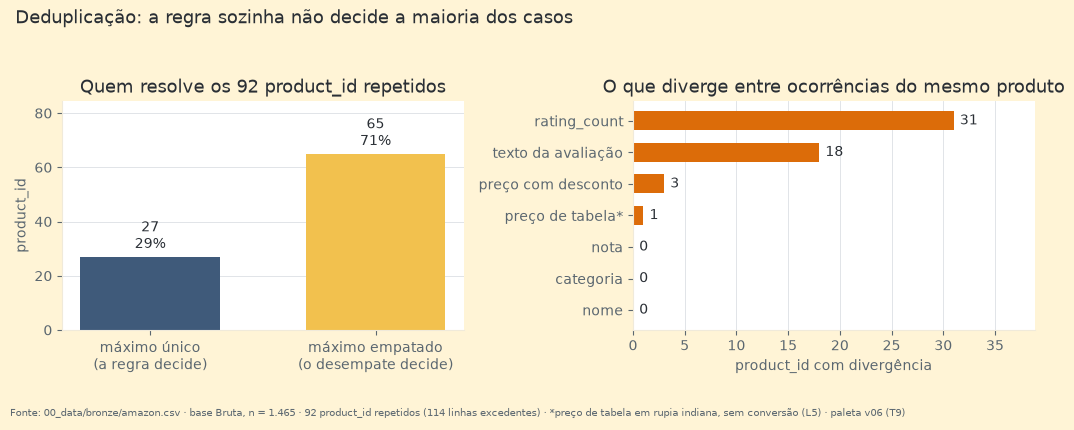

In [5]:
fig, eixos = plt.subplots(1, 2, figsize=(10.5, 4.2))

# Painel esquerdo — quem decide cada um dos 92 product_id repetidos
rotulos = ["máximo único\n(a regra decide)", "máximo empatado\n(o desempate decide)"]
valores = [max_unico, max_empatado]
cores = [CATEGORICA[1], CHAMADAS["destaque"]]
barras = eixos[0].bar(rotulos, valores, color=cores, width=0.62)
for barra, valor in zip(barras, valores):
    eixos[0].text(barra.get_x() + barra.get_width() / 2, valor + 1.5,
                  f"{valor}\n{valor / len(repetidos):.0%}", ha="center", va="bottom",
                  fontsize=10, color=ESTRUTURA["tinta"])
eixos[0].set_title("Quem resolve os 92 product_id repetidos")
eixos[0].set_ylabel("product_id")
eixos[0].set_ylim(0, max(valores) * 1.30)
eixos[0].grid(axis="x", visible=False)

# Painel direito — o que diverge entre ocorrências do mesmo produto
# O preço com desconto e o texto da avaliação entram porque DIVERGEM, e o painel
# existe para mostrar o que diverge. Omiti-los deixava a figura em desacordo com a
# L6, que publica "preço de tabela em 1 produto e preço com desconto em 3".
campos = ["rating_count", "texto da avaliação", "preço com desconto",
          "preço de tabela*", "nota", "categoria", "nome"]
divs = [divergem_aval,
        int(repetidas.groupby("product_id").review_content.nunique(dropna=False).gt(1).sum()),
        int(repetidas.groupby("product_id").preco_desc.nunique(dropna=False).gt(1).sum()),
        int(repetidas.groupby("product_id").preco_tab.nunique(dropna=False).gt(1).sum()),
        divergem_nota, divergem_cat, divergem_nome]
cor_barra = [CHAMADAS["atencao"] if d else CATEGORICA[2] for d in divs]
barras = eixos[1].barh(campos[::-1], divs[::-1], color=cor_barra[::-1], height=0.6)
for barra, valor in zip(barras, divs[::-1]):
    eixos[1].text(valor + 0.6, barra.get_y() + barra.get_height() / 2, str(valor),
                  va="center", fontsize=10, color=ESTRUTURA["tinta"])
eixos[1].set_title("O que diverge entre ocorrências do mesmo produto")
eixos[1].set_xlabel("product_id com divergência")
eixos[1].set_xlim(0, max(divs) * 1.22 + 1)
eixos[1].grid(axis="y", visible=False)

fig.suptitle("Deduplicação: a regra sozinha não decide a maioria dos casos",
             fontsize=13, color=ESTRUTURA["tinta"], x=0.015, ha="left", y=0.99)
fig.tight_layout(rect=[0, 0.055, 1, 0.94])
rodape(fig, "Fonte: 00_data/bronze/amazon.csv · base Bruta, n = 1.465 · 92 product_id repetidos "
            "(114 linhas excedentes) · *preço de tabela em rupia indiana, sem conversão (L5) · "
            "paleta v06 (T9)")
confere_visual(fig, "figura")          # T3 e T9 conferidos na figura
fig.savefig(IMAGENS / "fig_trat_01_empates_deduplicacao.png", dpi=200,
            bbox_inches="tight", facecolor=fig.get_facecolor())
print("gravado:", (IMAGENS / "fig_trat_01_empates_deduplicacao.png").relative_to(RAIZ))
plt.show()

## 3 · (b) O que muda **sem** o desempate

A pergunta correta não é "o desempate é elegante?", é "**quanto muda se ele não existir?**".
Para medir isso, monta-se a mesma base três vezes, mudando só a regra:

| Regra | Ordenação | O que representa |
|---|---|---|
| **Oficial** | `rating_count` ↓, depois `_ordem` ↑ | a regra do projeto |
| **Sem desempate** | `rating_count` ↓, depois `_ordem` ↓ | o outro resultado possível quando o máximo empata |
| **Primeira ocorrência** | `_ordem` ↑ | a alternativa "simples" discutida na seção 4 |

A variante "sem desempate" não é um erro de programação — é **o que a ordenação instável pode
devolver**. Ela serve para dar um nome e um número ao intervalo de indeterminação.

Duas medidas foram escolhidas para reportar o efeito, e não por acaso: a **mediana do preço de
tabela** (uma estatística de posição, que aparece em toda a análise de preço) e o **p-valor de
QA4** (`preço de tabela × nota`, Spearman) — a pergunta cujo resultado publicado é justamente
"**não há associação**". Se a regra de deduplicação mexesse no p-valor a ponto de cruzar 0,05,
a conclusão de QA4 dependeria de uma escolha de faxina. Não é o caso, e a célula abaixo mostra
de quanto é a margem.

In [6]:
PESSOAIS = ["user_id", "user_name"]          # T7 / LGPD
SEM_USO = ["img_link", "product_link"]       # sem uso analítico declarado
ORIGEM_TEXTO = ["discounted_price", "actual_price", "discount_percentage",
                "rating", "rating_count"]   # colunas texto já convertidas


def monta_silver(base, regra):
    """Aplica uma das três regras de deduplicação e devolve a camada silver."""
    if regra == "oficial":
        ordenada = base.sort_values(["avaliacoes", "_ordem"],
                                    ascending=[False, True], na_position="last")
    elif regra == "sem_desempate":
        ordenada = base.sort_values(["avaliacoes", "_ordem"],
                                    ascending=[False, False], na_position="last")
    elif regra == "primeira":
        ordenada = base.sort_values(["_ordem"], ascending=True)
    else:
        raise ValueError(f"regra desconhecida: {regra}")
    return (ordenada.drop_duplicates("product_id", keep="first")
                    .drop(columns=["_ordem"] + PESSOAIS + SEM_USO + ORIGEM_TEXTO))


def monta_gold_minima(silver):
    """Base analítica: só as linhas com nota E volume de avaliações válidos."""
    return silver[silver.nota.notna() & silver.avaliacoes.notna()].copy()


comparacao = []
camadas = {}
for regra in ["oficial", "sem_desempate", "primeira"]:
    s = monta_silver(b, regra)
    g = monta_gold_minima(s)
    rho, p = stats.spearmanr(g.preco_tab, g.nota)          # QA4
    camadas[regra] = (s, g)
    comparacao.append({
        "regra": regra,
        "n_silver": len(s),
        "n_gold": len(g),
        "mediana_preco_tabela": round(float(g.preco_tab.median()), 2),
        "mediana_preco_desconto": round(float(g.preco_desc.median()), 2),
        "soma_avaliacoes_silver": int(s.avaliacoes.sum()),
        "QA4_rho": round(float(rho), 4),
        "QA4_p": float(f"{p:.4g}"),
    })

comparacao = pd.DataFrame(comparacao)
print("IMPACTO DA REGRA DE DEDUPLICAÇÃO")
print("valores monetários em rupia indiana, sem símbolo e sem conversão (L5)\n")
print(comparacao.to_string(index=False))

IMPACTO DA REGRA DE DEDUPLICAÇÃO
valores monetários em rupia indiana, sem símbolo e sem conversão (L5)

        regra  n_silver  n_gold  mediana_preco_tabela  mediana_preco_desconto  soma_avaliacoes_silver  QA4_rho  QA4_p
      oficial      1351    1348                1795.0                   899.0                23802463   0.0323 0.2360
sem_desempate      1351    1348                1792.5                   899.0                23802463   0.0329 0.2277
     primeira      1351    1348                1795.0                   899.0                23802423   0.0323 0.2360


### 3.1 · O produto que move a mediana

O deslocamento da mediana do preço de tabela vem de **um único produto**. Vale nomeá-lo,
porque é o caso que transforma a regra abstrata em consequência concreta — e é o mesmo
citado em **L6**.

In [7]:
caso = b[b.product_id == "B096MSW6CT"][
    ["_ordem", "product_id", "preco_desc", "preco_tab", "desconto", "avaliacoes", "nota"]]
print("As três ocorrências de B096MSW6CT no bronze (rupia indiana, sem conversão — L5):\n")
print(caso.to_string(index=False))
print("\nrating_count idêntico nas três (7.928) — a regra 'maior rating_count' EMPATA.")
print("Com o desempate (menor _ordem) fica a linha 2  -> preço de tabela 1.899, desconto 90%.")
print("Sem o desempate pode ficar a linha 623         -> preço de tabela   999, desconto 80%.")

ofic, alt = camadas["oficial"][1], camadas["sem_desempate"][1]
difs = {}
for col in ["nota", "preco_tab", "preco_desc", "desconto", "avaliacoes",
            "category", "product_name", "review_id", "review_content"]:
    a_ = ofic.set_index("product_id")[col].astype(str)
    o_ = alt.set_index("product_id")[col].astype(str).reindex(a_.index)
    difs[col] = int((a_ != o_).sum())
print("\nProdutos que MUDAM de conteúdo quando o desempate desaparece "
      "(base Analítica, n = 1.348):")
for col, qtd in difs.items():
    print(f"  {col:<16} {qtd}")

As três ocorrências de B096MSW6CT no bronze (rupia indiana, sem conversão — L5):

 _ordem product_id  preco_desc  preco_tab  desconto  avaliacoes  nota
      2 B096MSW6CT       199.0     1899.0        90      7928.0   3.9
    379 B096MSW6CT       199.0      999.0        80      7928.0   3.9
    623 B096MSW6CT       199.0      999.0        80      7928.0   3.9

rating_count idêntico nas três (7.928) — a regra 'maior rating_count' EMPATA.
Com o desempate (menor _ordem) fica a linha 2  -> preço de tabela 1.899, desconto 90%.
Sem o desempate pode ficar a linha 623         -> preço de tabela   999, desconto 80%.

Produtos que MUDAM de conteúdo quando o desempate desaparece (base Analítica, n = 1.348):
  nota             0
  preco_tab        1
  preco_desc       1
  desconto         2
  avaliacoes       0
  category         0
  product_name     0
  review_id        3
  review_content   9


**Leitura.** Sem o desempate, a mediana do preço de tabela cai de **1.795** para **1.792,50**
(rupia indiana, base Analítica, n = 1.348) — porque um produto deixa de valer 1.899 e passa a
valer 999, o bastante para trocar o par central da série. O p-valor de **QA4** vai de
**0,236** para **0,2277**, com ρ de **+0,032** para **+0,033**.

Duas conclusões, e elas apontam em direções opostas de propósito:

1. **A conclusão de QA4 não depende da regra.** Em qualquer das variantes, ρ fica em torno de
   +0,03 e p fica muito acima de 0,05: **não há associação** entre preço de tabela e nota.
   A magnitude acompanha a significância (**T5**), e ambas são estáveis.
2. **A reprodutibilidade depende da regra.** Um número publicado — a mediana — muda de valor.
   Não é um número grande, mas é um número que aparece na base factual e que alguém vai
   conferir. Uma base que não devolve o mesmo dígito duas vezes não é auditável, e o custo de
   evitar isso é uma segunda chave de ordenação.

O desempate, portanto, não é defendido porque melhora a análise. É defendido porque **fixa**
a análise.

gravado: 02_results/tables/tab10_impacto_regra_dedup.csv
gravado: 02_results/images/fig_trat_02_impacto_regra_dedup.png


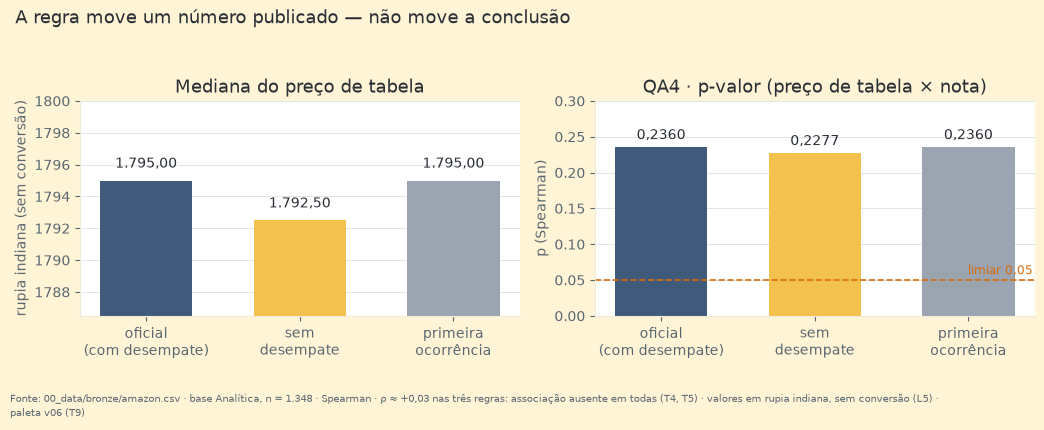

In [8]:
tab_impacto = comparacao.copy()
tab_impacto["base"] = "Bruta 1.465 -> silver / Analitica"
tab_impacto["moeda"] = "rupia indiana, sem conversao (L5)"
tab_impacto["nota_metodo"] = "QA4 = Spearman preco de tabela x nota, n = 1.348"
tab_impacto.to_csv(TABELAS / "tab10_impacto_regra_dedup.csv", index=False, encoding="utf-8")
print("gravado:", (TABELAS / "tab10_impacto_regra_dedup.csv").relative_to(RAIZ))

fig, eixos = plt.subplots(1, 2, figsize=(10.5, 4.2))
nomes = ["oficial\n(com desempate)", "sem\ndesempate", "primeira\nocorrência"]
cores3 = [CATEGORICA[1], CHAMADAS["destaque"], CATEGORICA[2]]

med = comparacao.mediana_preco_tabela.tolist()
barras = eixos[0].bar(nomes, med, color=cores3, width=0.6)
for barra, valor in zip(barras, med):
    # ponto de milhar e vírgula decimal: 1795.0 -> "1.795,00"
    eixos[0].text(barra.get_x() + barra.get_width() / 2, valor + 0.6,
                  f"{valor:,.2f}".replace(",", "@").replace(".", ",").replace("@", "."),
                  ha="center", va="bottom", fontsize=10, color=ESTRUTURA["tinta"])
eixos[0].set_ylim(min(med) - 6, max(med) + 5)
eixos[0].set_title("Mediana do preço de tabela")
eixos[0].set_ylabel("rupia indiana (sem conversão)")
eixos[0].grid(axis="x", visible=False)

pv = comparacao.QA4_p.tolist()
barras = eixos[1].bar(nomes, pv, color=cores3, width=0.6)
for barra, valor in zip(barras, pv):
    eixos[1].text(barra.get_x() + barra.get_width() / 2, valor + 0.006,
                  f"{valor:.4f}".replace(".", ","), ha="center", va="bottom",
                  fontsize=10, color=ESTRUTURA["tinta"])
eixos[1].axhline(0.05, color=CHAMADAS["atencao"], linewidth=1.2, linestyle="--")
eixos[1].text(2.42, 0.058, "limiar 0,05", fontsize=8.5, color=CHAMADAS["atencao"], ha="right")
eixos[1].set_ylim(0, 0.30)
eixos[1].set_title("QA4 · p-valor (preço de tabela × nota)")
eixos[1].set_ylabel("p (Spearman)")
eixos[1].grid(axis="x", visible=False)

fig.suptitle("A regra move um número publicado — não move a conclusão",
             fontsize=13, color=ESTRUTURA["tinta"], x=0.015, ha="left", y=0.99)
fig.tight_layout(rect=[0, 0.055, 1, 0.94])
rodape(fig, "Fonte: 00_data/bronze/amazon.csv · base Analítica, n = 1.348 · Spearman · "
            "ρ ≈ +0,03 nas três regras: associação ausente em todas (T4, T5) · "
            "valores em rupia indiana, sem conversão (L5) · paleta v06 (T9)")
confere_visual(fig, "figura")          # T3 e T9 conferidos na figura
fig.savefig(IMAGENS / "fig_trat_02_impacto_regra_dedup.png", dpi=200,
            bbox_inches="tight", facecolor=fig.get_facecolor())
print("gravado:", (IMAGENS / "fig_trat_02_impacto_regra_dedup.png").relative_to(RAIZ))
plt.show()

## 4 · (c) Por que **não** se adotou a primeira ocorrência

"Fique com a primeira linha de cada `product_id`" é a regra mais simples possível: uma chamada,
sem ordenação, sem desempate, determinística por construção. Ela foi considerada e **descartada**.
Os três motivos, do mais forte para o mais fraco:

**1 · Ela escolhe deliberadamente a leitura mais velha.** As ocorrências repetidas são a mesma
coleta em instantes diferentes, e `rating_count` só cresce. Ficar com a primeira é ficar com o
contador defasado — e, junto com ele, com o bloco de avaliações menos completo. A regra oficial
fica com o registro mais recente; a primeira ocorrência fica com o mais antigo. Entre duas
regras igualmente determinísticas, escolhe-se a que preserva mais informação.

**2 · Ela perde volume de avaliações, de forma mensurável.** A célula abaixo quantifica: a soma
de `rating_count` cai, e um conjunto de produtos passa a carregar um número menor do que o
disponível na origem. É pouco — e é exatamente por ser pouco que o argumento precisa ser
numérico, não retórico.

**3 · Ela não é mais simples de justificar.** A economia é de uma linha de código. O custo é ter
de explicar, na banca, por que a base descartou o dado mais novo tendo o mais novo em mãos.

**O que este notebook não faz:** afirmar que a primeira ocorrência produziria conclusões erradas.
Não produziria. As medidas agregadas praticamente não se movem — e esse é o achado honesto a
publicar. A regra foi escolhida por **preservação de informação**, não por diferença de resultado.

In [9]:
prim = camadas["primeira"][1]
ofic = camadas["oficial"][1]

difs_primeira = {}
for col in ["nota", "preco_tab", "preco_desc", "desconto", "avaliacoes",
            "category", "product_name", "review_id", "review_content"]:
    a_ = ofic.set_index("product_id")[col].astype(str)
    o_ = prim.set_index("product_id")[col].astype(str).reindex(a_.index)
    difs_primeira[col] = int((a_ != o_).sum())

soma_ofic = int(camadas["oficial"][0].avaliacoes.sum())
soma_prim = int(camadas["primeira"][0].avaliacoes.sum())
perda = soma_ofic - soma_prim

print("REGRA OFICIAL  ×  PRIMEIRA OCORRÊNCIA   (base Analítica, n = 1.348)\n")
for col, qtd in difs_primeira.items():
    marca = "  <-- perda de informação" if col == "avaliacoes" else ""
    print(f"  produtos com {col:<16} diferente: {qtd}{marca}")

print(f"\nVolume de avaliações (T6 — nunca vendas), base Produtos, n = 1.351:")
print(f"  regra oficial ........ {soma_ofic:,}".replace(",", "."))
print(f"  primeira ocorrência .. {soma_prim:,}".replace(",", "."))
print(f"  diferença ............ {perda} avaliações em {soma_ofic:,}".replace(",", ".")
      + f" = {perda / soma_ofic:.4%}")
print("\nNota, categoria e nome: idênticos nas duas regras. A escolha NÃO afeta satisfação")
print("nem agrupamento — afeta qual snapshot do contador e qual bloco de texto sobrevive.")

REGRA OFICIAL  ×  PRIMEIRA OCORRÊNCIA   (base Analítica, n = 1.348)

  produtos com nota             diferente: 0
  produtos com preco_tab        diferente: 0
  produtos com preco_desc       diferente: 1
  produtos com desconto         diferente: 1
  produtos com avaliacoes       diferente: 15  <-- perda de informação
  produtos com category         diferente: 0
  produtos com product_name     diferente: 0
  produtos com review_id        diferente: 3
  produtos com review_content   diferente: 4

Volume de avaliações (T6 — nunca vendas), base Produtos, n = 1.351:
  regra oficial ........ 23.802.463
  primeira ocorrência .. 23.802.423
  diferença ............ 40 avaliações em 23.802.463 = 0.0002%

Nota, categoria e nome: idênticos nas duas regras. A escolha NÃO afeta satisfação
nem agrupamento — afeta qual snapshot do contador e qual bloco de texto sobrevive.


**Leitura.** A primeira ocorrência deixa **15 produtos** com um `rating_count` menor do que o
disponível na origem e descarta **40 avaliações** de um total de **23.802.463** (base Produtos,
n = 1.351) — **0,0002%**. Imaterial para qualquer agregado, como a evidência do projeto já
registrava. Mas a diferença existe, tem sinal conhecido e aponta sempre para o mesmo lado:
a primeira ocorrência perde, nunca ganha. Com custo zero de implementação, não há razão para
preferir a regra que perde.

O efeito prático mais visível não é numérico: **4 produtos** ficam com um bloco de avaliações
diferente. Isso alcança o corpus de texto (notebook 05), não as medidas.

## 5 · (d) Remoção de `user_id` e `user_name` — **T7** e LGPD

`user_id` e `user_name` são **dado pessoal**. A regra **T7** é categórica: não aparecem em
visual, tabela, slide ou frame do vídeo. Este notebook vai um passo além do "não exibir":
as colunas **não atravessam a camada bronze**. São descartadas no mesmo `drop` que constrói a
silver, antes de qualquer análise.

**Decisão:** descartar na construção da silver.
**Alternativas descartadas:**
- *Anonimizar com hash.* Rejeitada: um hash de identificador continua sendo uma chave de
  ligação entre registros — pseudonimização, não anonimização — e a base **não tem nenhuma
  pergunta** (Q1–Q8, QA1–QA7) que exija seguir o mesmo usuário entre produtos. Guardar
  capacidade de reidentificação sem uso analítico é risco sem contrapartida.
- *Manter na silver e filtrar na hora de exibir.* Rejeitada: transforma uma regra estrutural
  em disciplina de quem escreve o gráfico. Basta um `df.head()` distraído numa apresentação.
  O que não está no arquivo não vaza.

Descartadas junto, por motivo diferente (**sem uso analítico declarado**, não privacidade):
`img_link` e `product_link`.

A célula abaixo **prova** a ausência — em todas as camadas de saída, inclusive no corpus de
reviews. É uma asserção, não uma inspeção visual.

In [10]:
s_oficial, g_oficial = camadas["oficial"]

print("Colunas descartadas da silver:")
print(f"  por T7 / LGPD ............ {PESSOAIS}")
print(f"  sem uso analítico ........ {SEM_USO}")
print(f"  texto já convertido ...... {ORIGEM_TEXTO}")

# Rótulos precisos: `s_oficial` é a silver CONCEITUAL (12 colunas — as 9 versionadas
# mais as 3 de texto livre, que vão para produtos_texto.csv, fora do git). `g_oficial`
# é o RECORTE ANALÍTICO dessa silver (os 1.348), ainda sem as 9 colunas derivadas —
# a gold em disco tem 17. Chamar `g_oficial` de "gold" seria erro de rótulo.
for nome, quadro in [("silver conceitual (9 versionadas + 3 de texto)", s_oficial),
                     ("recorte analítico da silver, antes dos derivados", g_oficial)]:
    vazou = [c for c in PESSOAIS if c in quadro.columns]
    assert not vazou, f"T7 violada: {vazou} presente em {nome}"
    print(f"\n{nome}: {quadro.shape[0]} linhas × {quadro.shape[1]} colunas · "
          f"nenhuma coluna pessoal (T7 OK)")

print("\ncolunas da silver:", list(s_oficial.columns))

import pandas as _pd
_g_disco = _pd.read_csv(GOLD)
_s_disco = _pd.read_csv(SILVER)
print(f"\nEM DISCO · silver/produtos.csv .... {_s_disco.shape[0]} × {_s_disco.shape[1]}")
print(f"EM DISCO · gold/base_analitica.csv  {_g_disco.shape[0]} × {_g_disco.shape[1]}"
      f"  ({len(_g_disco.columns) - len(_s_disco.columns) + 1} colunas derivadas)")
assert _s_disco.shape[1] == 9,  f"silver versionada deveria ter 9 colunas, tem {_s_disco.shape[1]}"
assert _g_disco.shape[1] == 17, f"gold deveria ter 17 colunas, tem {_g_disco.shape[1]}"
print("\nconferido contra o disco: 9 e 17 ✅")


Colunas descartadas da silver:
  por T7 / LGPD ............ ['user_id', 'user_name']
  sem uso analítico ........ ['img_link', 'product_link']
  texto já convertido ...... ['discounted_price', 'actual_price', 'discount_percentage', 'rating', 'rating_count']

silver conceitual (9 versionadas + 3 de texto): 1351 linhas × 12 colunas · nenhuma coluna pessoal (T7 OK)

recorte analítico da silver, antes dos derivados: 1348 linhas × 12 colunas · nenhuma coluna pessoal (T7 OK)

colunas da silver: ['product_id', 'product_name', 'category', 'about_product', 'review_id', 'review_title', 'review_content', 'preco_desc', 'preco_tab', 'desconto', 'avaliacoes', 'nota']

EM DISCO · silver/produtos.csv .... 1351 × 9
EM DISCO · gold/base_analitica.csv  1348 × 17  (9 colunas derivadas)

conferido contra o disco: 9 e 17 ✅


## 6 · (e) A reconciliação 1.465 → 1.351 → 1.350 → 1.349 → 1.348

As cinco bases oficiais do projeto e a passagem de uma para a outra. **T3** exige que todo
número declare qual delas usou — por isso a reconciliação precisa fechar por subtração, sem
resto e sem arredondamento.

| Base | *n* | Sai de | O que foi removido |
|---|---|---|---|
| **Bruta** | 1.465 | — | nada; é o bronze |
| **Produtos** | 1.351 | Bruta | **−114** linhas excedentes por `product_id` |
| **Nota válida** | 1.350 | Produtos | **−1** `rating` inválido (valor `\|`) |
| **Engajamento válido** | 1.349 | Produtos | **−2** `rating_count` nulos |
| **Analítica** | 1.348 | — | **−2** `rating_count` nulos, sem sobreposição com a nota |

O detalhe que faz a conta fechar: o registro de `rating` inválido e os dois de `rating_count`
nulo são **três produtos distintos** — não há sobreposição. Por isso 1.351 − 1 − 2 = 1.348, e
as bases intermediárias "Nota válida" (1.350) e "Engajamento válido" (1.349) existem como
denominadores legítimos para análises que dependem de **uma só** das duas variáveis.

In [11]:
n_produtos = len(s_oficial)
sem_nota = int(s_oficial.nota.isna().sum())
sem_aval = int(s_oficial.avaliacoes.isna().sum())
sobreposicao = int((s_oficial.nota.isna() & s_oficial.avaliacoes.isna()).sum())

n_nota_valida = n_produtos - sem_nota
n_engaj_valido = n_produtos - sem_aval
n_analitica = len(g_oficial)

reconciliacao = pd.DataFrame([
    ("Bruta", n_bruta, "-", "origem intocada", "qualidade da origem"),
    ("Produtos", n_produtos, f"-{n_bruta - n_produtos}",
     "linhas excedentes por product_id", "contagem de portfólio"),
    ("Nota válida", n_nota_valida, f"-{sem_nota}",
     "rating inválido (valor '|')", "análises só de rating"),
    ("Engajamento válido", n_engaj_valido, f"-{sem_aval}",
     "rating_count nulo", "análises só de volume de avaliações"),
    ("Analítica", n_analitica, f"-{sem_nota + sem_aval}",
     "nota inválida + volume nulo, sem sobreposição", "PADRÃO — toda análise cruzada"),
], columns=["base", "n", "delta_sobre_produtos", "removido", "quando_usar"])

print("RECONCILIAÇÃO DAS CINCO BASES OFICIAIS\n")
print(reconciliacao.to_string(index=False))
print(f"\nsobreposição entre nota inválida e volume nulo: {sobreposicao} produto(s)")
print(f"conferência: {n_produtos} - {sem_nota} - {sem_aval} = "
      f"{n_produtos - sem_nota - sem_aval}  (esperado 1.348)")

reconciliacao.to_csv(TABELAS / "tab11_reconciliacao_camadas.csv", index=False, encoding="utf-8")
print("\ngravado:", (TABELAS / "tab11_reconciliacao_camadas.csv").relative_to(RAIZ))

RECONCILIAÇÃO DAS CINCO BASES OFICIAIS

              base    n delta_sobre_produtos                                      removido                         quando_usar
             Bruta 1465                    -                               origem intocada                 qualidade da origem
          Produtos 1351                 -114              linhas excedentes por product_id               contagem de portfólio
       Nota válida 1350                   -1                   rating inválido (valor '|')               análises só de rating
Engajamento válido 1349                   -2                             rating_count nulo análises só de volume de avaliações
         Analítica 1348                   -3 nota inválida + volume nulo, sem sobreposição       PADRÃO — toda análise cruzada

sobreposição entre nota inválida e volume nulo: 0 produto(s)
conferência: 1351 - 1 - 2 = 1348  (esperado 1.348)

gravado: 02_results/tables/tab11_reconciliacao_camadas.csv


## 7 · Gold — os derivados, e a razão de cada um

A camada gold não traz dado novo. Traz **decisões já tomadas**, materializadas em coluna, para
que notebook, dashboard e vídeo leiam o mesmo valor em vez de recalcularem cada um o seu.

| Derivado | Cálculo | Por quê |
|---|---|---|
| `nota_corrigida` | limite inferior de **Wilson** a 95%, remapeado de 1–5 | **T1** e **D-3**: sem correção, um produto com 5 avaliações lidera o ranking de "melhores". Wilson foi preferido à média bayesiana por não exigir arbitrar um *prior* — todo *prior* vira pergunta na banca |
| `categoria_n1` / `categoria_n2` | 1º e 2º nós de `category`, separados por `\|` | nível 1 = família, nível 2 = unidade de comparação |
| `engajamento` | ≥ p90 = alto · < mediana = baixo | cortes fechados: p90 = 36.384, mediana = 4.740. **T6** — volume de avaliações |
| `satisfacao` | < 4,0 baixa · ≥ 4,3 alta | cortes fechados da base factual |
| `q5_risco_vitrine` | p90 de volume **e** nota < 4,0 | quadrante de Q5 |
| `q6_subexplorado` | nota ≥ 4,3 **e** volume < mediana | funil de Q6 (187); a lista acionável é a que continua ≥ 4,3 com Wilson (61, T1). Rótulo fechado em **D-1**: *bem avaliados com baixo volume de avaliações* |
| `faixa_desconto` | 5 faixas de 20 p.p. | leitura comercial do desconto |
| `pareto_80` | menor conjunto que soma 80% do volume | QA2 |

**Alternativa descartada em `engajamento`:** quartis. Rejeitada porque o corte de negócio
declarado é p90 (cauda) contra mediana (metade inferior) — quartis produziriam quatro grupos
sem correspondência com nenhuma pergunta do escopo.

**Sobre `pareto_80`:** o conjunto é montado por soma acumulada decrescente, e a fronteira
**inclui** o produto que cruza os 80% — do contrário o grupo somaria menos de 80% e o rótulo
mentiria. Esse `+1` é o que separa 305 de **306**.

In [12]:
def wilson(nota, n, z=1.96):
    """T1 — limite inferior de Wilson a 95%, com a nota normalizada de 1–5 para 0–1
    e devolvida na escala original. Penaliza o produto com poucas avaliações."""
    p = (nota - 1) / 4.0
    d = 1 + z ** 2 / n
    centro = p + z ** 2 / (2 * n)
    margem = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2))
    return ((centro - margem) / d) * 4 + 1


g = g_oficial.copy()
p90 = g.avaliacoes.quantile(0.90)
mediana_aval = g.avaliacoes.median()

g["nota_corrigida"] = wilson(g.nota, g.avaliacoes)
g["categoria_n1"] = g.category.str.split("|").str[0]
g["categoria_n2"] = g.category.str.split("|").str[:2].str.join(" | ")
g["engajamento"] = np.where(g.avaliacoes >= p90, "alto",
                            np.where(g.avaliacoes < mediana_aval, "baixo", "intermediario"))
g["satisfacao"] = np.where(g.nota < 4.0, "baixa", np.where(g.nota >= 4.3, "alta", "media"))
g["q5_risco_vitrine"] = (g.avaliacoes >= p90) & (g.nota < 4.0)
g["q6_subexplorado"] = (g.nota >= 4.3) & (g.avaliacoes < mediana_aval)
g["faixa_desconto"] = pd.cut(g.desconto, [0, 20, 40, 60, 80, 100],
                             labels=["0-20%", "21-40%", "41-60%", "61-80%", "81-100%"],
                             include_lowest=True)
acum = g.avaliacoes.sort_values(ascending=False).cumsum()
limite = acum[acum < 0.8 * g.avaliacoes.sum()].index
g["pareto_80"] = g.index.isin(limite) | (g.index == acum.index[len(limite)])

print("CORTES APLICADOS · base Analítica, n = 1.348")
print(f"  p90 de volume de avaliações ... {p90:,.0f}".replace(",", ".")
      + "   (engajamento alto)")
print(f"  mediana de volume ............. {mediana_aval:,.0f}".replace(",", ".")
      + "   (engajamento baixo abaixo dela)")
print(f"  satisfação baixa (nota < 4,0) .. {int((g.nota < 4.0).sum())} produtos "
      f"({(g.nota < 4.0).mean():.1%})".replace(".", ","))
print(f"  satisfação alta (nota >= 4,3) .. {int((g.nota >= 4.3).sum())} produtos")
print("\nQUADRANTES E CONCENTRAÇÃO")
print(f"  Q5 · alto volume + nota < 4,0 .......... {int(g.q5_risco_vitrine.sum())} produtos")
print(f"  Q6 · nota >= 4,3 + volume < mediana .... {int(g.q6_subexplorado.sum())} produtos")
print(f"  Pareto 80% do volume ................... {int(g.pareto_80.sum())} produtos "
      f"({g.pareto_80.mean():.1%})".replace(".", ","))

CORTES APLICADOS · base Analítica, n = 1.348
  p90 de volume de avaliações ... 36.384   (engajamento alto)
  mediana de volume ............. 4.740   (engajamento baixo abaixo dela)
  satisfação baixa (nota < 4,0) ,, 339 produtos (25,1%)
  satisfação alta (nota >= 4,3) .. 418 produtos

QUADRANTES E CONCENTRAÇÃO
  Q5 · alto volume + nota < 4,0 .......... 19 produtos
  Q6 · nota >= 4,3 + volume < mediana .... 187 produtos
  Pareto 80% do volume ,,,,,,,,,,,,,,,,,,, 306 produtos (22,7%)


### 7.1 · Corpus textual — **T8**

O bloco de avaliações vem concatenado numa célula. Ao explodi-lo aparecem **referências de
avaliação**; ao deduplicar por `review_id` aparecem **reviews individuais**. As duas contagens
diferem em 14%, e trocar uma pela outra infla o tamanho declarado do corpus.

**T8** obriga as três declarações: **unidade**, **deduplicação por `review_id`** e
**truncamento em 8** (**L1**). O vocabulário do dicionário de dados é o único aceito —
"bloco de review", "referência de avaliação", "review individual".

In [13]:
explodido = g.assign(_r=g.review_id.str.split(",")).explode("_r")
explodido["_r"] = explodido._r.str.strip()

reviews = (explodido[["_r", "product_id", "categoria_n1", "nota", "satisfacao"]]
           .rename(columns={"_r": "review_id"})
           .drop_duplicates("review_id"))

por_produto = explodido.groupby("product_id").size()

print("CORPUS TEXTUAL · base Analítica, n = 1.348 produtos (T8)")
print(f"  blocos de review (1 por produto) ..... {len(g)}")
print(f"  referências de avaliação (explodidas) . {len(explodido)}")
print(f"  reviews individuais (review_id único) . {reviews.review_id.nunique()}")
print(f"  referências repetidas ................. {len(explodido) - reviews.review_id.nunique()}"
      f" ({(len(explodido) - reviews.review_id.nunique()) / len(explodido):.1%})".replace(".", ","))
print(f"  review_id presente em mais de um produto {int(explodido.groupby('_r').product_id.nunique().gt(1).sum())}")
print(f"\nTRUNCAMENTO (L1): média de {por_produto.mean():.2f}".replace(".", ",")
      + f" avaliações por produto · máximo {int(por_produto.max())}")
print("  O texto NÃO é amostra aleatória: é o recorte que o marketplace exibiu na vitrine.")
print("  Nenhum achado deste corpus pode ser lido como 'a maioria dos clientes pensa que...'.")
assert "user_id" not in reviews.columns and "user_name" not in reviews.columns, "T7 violada"
print("\nT7: o corpus não carrega identificador de consumidor.")

CORPUS TEXTUAL · base Analítica, n = 1.348 produtos (T8)
  blocos de review (1 por produto) ..... 1348
  referências de avaliação (explodidas) . 10588
  reviews individuais (review_id único) . 9255
  referências repetidas ,,,,,,,,,,,,,,,,, 1333 (12,6%)
  review_id presente em mais de um produto 759

TRUNCAMENTO (L1): média de 7,85 avaliações por produto · máximo 8
  O texto NÃO é amostra aleatória: é o recorte que o marketplace exibiu na vitrine.
  Nenhum achado deste corpus pode ser lido como 'a maioria dos clientes pensa que...'.

T7: o corpus não carrega identificador de consumidor.


## 8 · Chamada do script oficial e comparação das camadas

Até aqui o notebook reconstruiu tudo **em memória**. Agora `src/prepara_dados.py` é executado
como processo separado — do jeito que qualquer pessoa executaria — e as camadas que ele grava
em disco são comparadas contra o que este notebook produziu.

Se o notebook e o script divergirem, um dos dois está errado e a divergência aparece aqui,
não na banca. A comparação é feita de duas formas, porque elas falham por motivos diferentes:

1. **SHA-256 antes × depois**: prova que a reexecução é **idempotente** — rodar o script duas
   vezes não muda o arquivo.
2. **Comparação campo a campo** do que o notebook tem em memória contra o CSV gravado: prova
   que a **documentação corresponde ao código**, e não apenas a si mesma.

### Nota de método — por que a comparação numérica tem tolerância
A comparação campo a campo **não** pode ser feita convertendo número em texto, e a razão é
específica: o valor vai para o CSV como decimal e volta como binário, e a ida e volta não
preserva o último bit. `nota_corrigida` é o caso — em 110 dos 1.348 produtos a memória guarda
`3,7915383038990838` e o disco devolve `3,791538303899084`. **A maior folga observada é da
ordem de 1e-16**, ou seja, o próprio épsilon da dupla precisão: é o CSV, não o cálculo.
Some-se que `NaN != NaN` por definição do IEEE 754, o que faria os 2 `rating_count` nulos e
o 1 `rating` inválido aparecerem como divergência justamente onde ambos os lados concordam
que o dado **não existe**.

Por isso a função abaixo compara **coluna numérica por valor**, com tolerância de `1e-9` e
tratando ausente igual a ausente, e **coluna de texto exatamente**. A tolerância é sete
ordens de grandeza maior que o ruído medido e muitas ordens menor que qualquer diferença
com significado analítico — uma divergência real de regra moveria a nota na segunda casa
decimal, não na décima quinta. A maior folga é impressa a cada comparação, para que o leitor
confira que ela continua no nível do ruído e não cresceu.

In [14]:
antes = {caminho: sha256(caminho) for caminho in [SILVER, GOLD, GOLD_REV]
         if caminho.exists()}

try:
    execucao = subprocess.run(
        [sys.executable, str(RAIZ / "src" / "prepara_dados.py")],
        capture_output=True, text=True, timeout=600, cwd=str(RAIZ), check=False)
except subprocess.TimeoutExpired as erro:
    raise RuntimeError("src/prepara_dados.py não terminou em 600 s") from erro

print(execucao.stdout)
if execucao.stderr.strip():
    print("--- stderr ---\n", execucao.stderr)
assert execucao.returncode == 0, f"src/prepara_dados.py falhou (código {execucao.returncode})"

depois = {caminho: sha256(caminho) for caminho in [SILVER, GOLD, GOLD_REV]}
print("\nIDEMPOTÊNCIA · SHA-256 das camadas antes e depois da reexecução")
for caminho, h in depois.items():
    marca = ("idêntico" if antes.get(caminho) == h
             else ("REESCRITO" if caminho in antes else "criado agora"))
    print(f"  {str(caminho.relative_to(RAIZ)):<32} {h[:16]}…  {marca}")

BRONZE
  00_data/bronze/amazon.csv
  SHA-256 4ba126c4ba8edd35e62e94ce1c853073d832de380184ab4f5f97d1e314882c77
  integridade conferida · o arquivo não será escrito por este script
  1465 linhas × 16 colunas, tudo texto

SILVER
  00_data/silver/produtos.csv
  00_data/silver/produtos_texto.csv
  1351 produtos · texto livre · NÃO versionado (nomes escritos nas avaliações)
  1351 produtos deduplicados e tipados
  removidas: user_id, user_name (T7/LGPD) · img_link, product_link (sem uso)
  texto livre separado: about_product, review_title, review_content

GOLD
  00_data/gold/base_analitica.csv
  1348 produtos — base analítica · 17 colunas com derivados
  cortes aplicados: p90 = 36.384 · mediana = 4.740
  Q5 = 19 · Q6 = 187 · Pareto 80% = 306
  00_data/gold/reviews.csv
  9255 reviews distintos (de 10588 referências) · deduplicado por review_id (T8)

Reconciliação: 1465 (bronze) → 1351 (silver) → 1348 (gold)
Nenhuma coluna pessoal atravessa o bronze. Valores monetários sem símbolo, em rupia in

In [15]:
# Comparação campo a campo: notebook (memória) × script (disco).
silver_disco = pd.read_csv(SILVER)
gold_disco = pd.read_csv(GOLD)
reviews_disco = pd.read_csv(GOLD_REV)

silver_nb = s_oficial.drop(columns=[c for c in TEXTO_LIVRE
                                    if c in s_oficial.columns]).reset_index(drop=True)
gold_nb = g.drop(columns=["review_id", "review_title", "review_content",
                          "about_product"]).reset_index(drop=True)
reviews_nb = reviews.reset_index(drop=True)

TOLERANCIA = 1e-9   # ver a nota de método logo acima: ida e volta pelo CSV


def compara(nome, esquerda, direita):
    """Compara dois quadros por conteúdo, tolerando ordem de linha e tipo de leitura.

    Coluna numérica é comparada por VALOR, com tolerância de 1e-9 e tratando
    ausente == ausente. Comparar número como texto acusaria divergência onde não
    há: o CSV devolve o último bit diferente (3,791538303899084 contra
    3,7915383038990838) e `NaN != NaN` por definição do IEEE 754.
    Coluna de texto é comparada exatamente, com o ausente normalizado.
    """
    assert list(esquerda.columns) == list(direita.columns), (
        f"{nome}: colunas diferentes\n  notebook: {list(esquerda.columns)}"
        f"\n  script  : {list(direita.columns)}")
    assert len(esquerda) == len(direita), (
        f"{nome}: {len(esquerda)} linhas no notebook × {len(direita)} no script")
    chave = "product_id" if "product_id" in esquerda.columns else "review_id"
    e = esquerda.sort_values(chave).reset_index(drop=True)
    d = direita.sort_values(chave).reset_index(drop=True)

    divergentes = []
    maior_folga = 0.0
    for col in e.columns:
        col_e, col_d = e[col], d[col]
        numerica = (pd.api.types.is_numeric_dtype(col_e)
                    and pd.api.types.is_numeric_dtype(col_d)
                    and not pd.api.types.is_bool_dtype(col_e))
        if numerica:
            a_ = pd.to_numeric(col_e, errors="coerce").to_numpy(dtype=float)
            b_ = pd.to_numeric(col_d, errors="coerce").to_numpy(dtype=float)
            iguais = np.isclose(a_, b_, rtol=0, atol=TOLERANCIA, equal_nan=True)
            ambos = ~np.isnan(a_) & ~np.isnan(b_)
            if ambos.any():
                maior_folga = max(maior_folga, float(np.abs(a_[ambos] - b_[ambos]).max()))
        else:
            a_ = col_e.astype("string").fillna("<ausente>").to_numpy()
            b_ = col_d.astype("string").fillna("<ausente>").to_numpy()
            iguais = a_ == b_
        n_dif = int((~iguais).sum())
        if n_dif:
            divergentes.append((col, n_dif))

    print(f"  {nome:<16} {len(e):>5} linhas × {e.shape[1]:>2} colunas · "
          + ("IDÊNTICO ao script" if not divergentes else f"DIVERGE em {divergentes}")
          + f"  · maior folga numérica {maior_folga:.2e}")
    return divergentes

print("NOTEBOOK (memória)  ×  src/prepara_dados.py (disco)")
falhas = []
falhas += compara("silver", silver_nb, silver_disco)
falhas += compara("gold analítica", gold_nb, gold_disco)
falhas += compara("gold reviews", reviews_nb, reviews_disco)
assert not falhas, f"o notebook não reproduz o script: {falhas}"
print("\nAs camadas saem idênticas. A documentação acima descreve o código que roda.")

NOTEBOOK (memória)  ×  src/prepara_dados.py (disco)
  silver            1351 linhas ×  9 colunas · IDÊNTICO ao script  · maior folga numérica 0.00e+00
  gold analítica    1348 linhas × 17 colunas · IDÊNTICO ao script  · maior folga numérica 8.88e-16
  gold reviews      9255 linhas ×  5 colunas · IDÊNTICO ao script  · maior folga numérica 0.00e+00

As camadas saem idênticas. A documentação acima descreve o código que roda.


## 9 · Célula final de validação

Toda contagem deste notebook conferida, por asserção, contra a
**base factual** (`method/definitions/base_factual_e_bases_de_calculo.md`) e contra
`src/valida_base.py`. Se qualquer número divergir, a célula falha e o
notebook não é entregável — é esse o ponto de ter uma célula final.

In [16]:
verificacoes = [
    # --- cinco bases oficiais -------------------------------------------------
    ("base Bruta", n_bruta, 1465),
    ("base Produtos (silver)", len(silver_disco), 1351),
    ("base Nota válida", n_nota_valida, 1350),
    ("base Engajamento válido", n_engaj_valido, 1349),
    ("base Analítica (gold)", len(gold_disco), 1348),
    ("colunas da silver versionada", len(silver_nb.columns), 9),
    ("colunas da gold analítica", gold_disco.shape[1], 17),
    # --- deduplicação ---------------------------------------------------------
    ("linhas excedentes", n_bruta - len(silver_disco), 114),
    ("product_id repetidos", len(repetidos), 92),
    ("repetidos com máximo único", max_unico, 27),
    ("repetidos com máximo empatado", max_empatado, 65),
    ("rating_count divergente", divergem_aval, 31),
    ("nota divergente entre ocorrências", divergem_nota, 0),
    ("categoria divergente entre ocorrências", divergem_cat, 0),
    ("produtos alterados pela 1a ocorrência · volume", difs_primeira["avaliacoes"], 15),
    ("produtos alterados pela 1a ocorrência · texto", difs_primeira["review_content"], 4),
    ("avaliações perdidas pela 1a ocorrência", perda, 40),
    ("soma do volume de avaliações (silver)", soma_ofic, 23802463),
    # --- cortes ---------------------------------------------------------------
    ("p90 de volume de avaliações", int(p90), 36384),
    ("mediana de volume de avaliações", int(mediana_aval), 4740),
    ("satisfação baixa (nota < 4,0)", int((gold_disco.nota < 4.0).sum()), 339),
    ("satisfação alta (nota >= 4,3)", int((gold_disco.nota >= 4.3).sum()), 418),
    # --- quadrantes -----------------------------------------------------------
    ("Q5 · risco de vitrine", int(gold_disco.q5_risco_vitrine.sum()), 19),
    ("Q6 · subexplorado", int(gold_disco.q6_subexplorado.sum()), 187),
    ("Pareto 80% do volume", int(gold_disco.pareto_80.sum()), 306),
    ("categorias n1 acima do piso n>=30",
     int((gold_disco.categoria_n1.value_counts() >= 30).sum()), 4),
    ("subcategorias n2 acima do piso n>=30",
     int((gold_disco.categoria_n2.value_counts() >= 30).sum()), 8),
    # --- corpus (T8) ----------------------------------------------------------
    ("referências de avaliação", len(explodido), 10588),
    ("reviews individuais (review_id único)", len(reviews_disco), 9255),
    ("referências repetidas", len(explodido) - len(reviews_disco), 1333),
    ("truncamento · máximo por produto", int(por_produto.max()), 8),
]

largura = max(len(nome) for nome, _, _ in verificacoes)
erros = []
print("VALIDAÇÃO FINAL · notebook 02 × base factual do projeto\n")
for nome, obtido, esperado in verificacoes:
    ok = obtido == esperado
    if not ok:
        erros.append((nome, obtido, esperado))
    # o separador de milhar é trocado só no número, nunca no rótulo
    valor = f"{obtido:>12,}".replace(",", ".")
    alvo = f"   esperado {esperado:,}".replace(",", ".") if not ok else ""
    print(f"  {'OK ' if ok else 'ERRO'}  {nome:<{largura}}  {valor}{alvo}")

# medidas contínuas — comparadas com tolerância, não por igualdade exata
continuas = [
    ("média de avaliações por produto (L1)", float(por_produto.mean()), 7.85, 0.01),
    ("mediana do preço de tabela · regra oficial",
     float(comparacao.loc[comparacao.regra == "oficial", "mediana_preco_tabela"].iloc[0]),
     1795.00, 0.01),
    ("mediana do preço de tabela · sem desempate",
     float(comparacao.loc[comparacao.regra == "sem_desempate", "mediana_preco_tabela"].iloc[0]),
     1792.50, 0.01),
    ("QA4 · p-valor com a regra oficial",
     float(comparacao.loc[comparacao.regra == "oficial", "QA4_p"].iloc[0]), 0.236, 0.001),
    ("QA4 · rho com a regra oficial",
     float(comparacao.loc[comparacao.regra == "oficial", "QA4_rho"].iloc[0]), 0.032, 0.001),
]
print()
for nome, obtido, esperado, tol in continuas:
    ok = abs(obtido - esperado) <= tol
    if not ok:
        erros.append((nome, obtido, esperado))
    # vírgula decimal e ponto de milhar, aplicados só ao número
    valor = f"{obtido:>12,.4f}".replace(",", "@").replace(".", ",").replace("@", ".")
    alvo = f"   esperado {esperado}" if not ok else ""
    print(f"  {'OK ' if ok else 'ERRO'}  {nome:<{largura}}  {valor}{alvo}")

# T7 — a asserção que não pode falhar em nenhuma circunstância
for nome, quadro in [("silver", silver_disco), ("gold", gold_disco), ("reviews", reviews_disco)]:
    vazou = [c for c in ["user_id", "user_name"] if c in quadro.columns]
    if vazou:
        erros.append((f"T7 · {nome}", vazou, []))
    print(f"\n  {'OK ' if not vazou else 'ERRO'}  T7 · {nome}: nenhum identificador de consumidor")

print("\nReconciliação publicada: "
      f"{n_bruta} -> {len(silver_disco)} -> {n_nota_valida} -> {n_engaj_valido} "
      f"-> {len(gold_disco)}")
print("Valores monetários em rupia indiana, sem símbolo e sem conversão (L5).")
print("rating_count = VOLUME DE AVALIAÇÕES, nunca vendas nem demanda (T6).")

assert not erros, f"{len(erros)} verificação(ões) falharam: {erros}"
print("\nTODAS AS VERIFICAÇÕES PASSARAM · notebook 02 fecha com a base factual.")

VALIDAÇÃO FINAL · notebook 02 × base factual do projeto

  OK   base Bruta                                             1.465
  OK   base Produtos (silver)                                 1.351
  OK   base Nota válida                                       1.350
  OK   base Engajamento válido                                1.349
  OK   base Analítica (gold)                                  1.348
  OK   colunas da silver versionada                               9
  OK   colunas da gold analítica                                 17
  OK   linhas excedentes                                        114
  OK   product_id repetidos                                      92
  OK   repetidos com máximo único                                27
  OK   repetidos com máximo empatado                             65
  OK   rating_count divergente                                   31
  OK   nota divergente entre ocorrências                          0
  OK   categoria divergente entre ocorrências              

---

## O que este notebook deixa decidido, e o que deixa em aberto

**Decidido e reproduzível**
- A regra de deduplicação é **determinística** e o desempate é **necessário**: ele decide
  65 dos 92 casos repetidos.
- Sem o desempate, um número publicado muda (mediana do preço de tabela: 1.795 → 1.792,50),
  embora a conclusão de **QA4** não mude (ρ ≈ +0,03, p > 0,22 nas três regras — **sem associação**).
- A primeira ocorrência descartaria 40 avaliações e o registro mais recente de 15 produtos,
  sem ganho algum.
- `user_id` e `user_name` **não existem** fora do bronze (**T7**).
- As cinco bases reconciliam sem resto: **1.465 → 1.351 → 1.350 → 1.349 → 1.348**.

**Decidido depois que este notebook foi escrito** (`method/open_decisions.md`)
- **D-1**, fechada em 24/09/2026 — visibilidade real não é observável nesta base. Adotou-se
  volume de avaliações abaixo da mediana como **proxy declarado de exposição**. A coluna
  `q6_subexplorado` marca o **funil de 187**; a lista acionável são os **61** que seguem com
  nota corrigida ≥ 4,3 (T1). O rótulo publicado é *bem avaliados com baixo volume de avaliações*.
- **D-5**, fechada em 01/10/2026 — `about_product` fica **fora** da camada gold: descreve a
  promessa do vendedor, não a percepção do consumidor.

**Próximo passo:** `03_medidas.ipynb` — cada medida com o valor de referência que o DAX terá
de reproduzir.